# 1. Data overview

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

olevel_df = pd.read_csv("./data/regression_bonus_practice_data.csv")
print(olevel_df.shape)
olevel_df.head()

(15900, 18)


,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
3,3,1,No,Clubs,Auditory,FEVM1T,Female,Yes,64.0,2.0,20.0,15.0,18.0,NaN,21:00,5:00,public transport,yellow
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow


In [19]:
olevel_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15900 entries, 0 to 15899
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               15900 non-null  int64  
 1   number_of_siblings  15900 non-null  int64  
 2   direct_admission    15900 non-null  str    
 3   CCA                 12071 non-null  str    
 4   learning_style      15900 non-null  str    
 5   student_id          15900 non-null  str    
 6   gender              15900 non-null  str    
 7   tuition             15900 non-null  str    
 8   final_test          15405 non-null  float64
 9   n_male              15900 non-null  float64
 10  n_female            15900 non-null  float64
 11  age                 15900 non-null  float64
 12  hours_per_week      15900 non-null  float64
 13  attendance_rate     15122 non-null  float64
 14  sleep_time          15900 non-null  str    
 15  wake_time           15900 non-null  str    
 16  mode_of_transpo

In [20]:
olevel_df.describe().T

,count,mean,std,min,25%,50%,75%,max
index,15900.0,7949.500000,4590.078975,0.0,3974.75,7949.5,11924.25,15899.0
number_of_siblings,15900.0,0.886541,0.751346,0.0,0.00,1.0,1.00,2.0
final_test,15405.0,67.165401,13.977879,32.0,56.00,68.0,78.00,100.0
n_male,15900.0,13.880000,6.552584,0.0,10.00,14.0,18.00,31.0
n_female,15900.0,8.906038,6.663852,0.0,4.00,8.0,13.00,31.0
age,15900.0,15.213459,1.758941,-5.0,15.00,15.0,16.00,16.0
hours_per_week,15900.0,10.312579,4.461861,0.0,7.00,9.0,14.00,20.0
attendance_rate,15122.0,93.270268,7.984230,40.0,92.00,95.0,97.00,100.0


# Summary:
# The raw data has 15,900 rows and 18 columns. Things to check from the summary:
# - `index` is just a row number and `student_id` is an identifier, so neither can predict scores.
# - `sleep_time` and `wake_time` are `hh:mm` strings and need converting before they can be used.
# - `age` has values below zero, which is impossible.

# 2. Data quality

# 2.1 Missing values

In [21]:
missing = olevel_df.isnull().sum()
missing = missing[missing > 0].to_frame("count")
missing["percent"] = (missing["count"] / len(olevel_df) * 100).round(1)
missing

,count,percent
CCA,3829,24.1
final_test,495,3.1
attendance_rate,778,4.9


# 2.2 Duplicate students

In [22]:
df = olevel_df.dropna(subset=["final_test"])

print("Rows:", len(df))
print("Unique students:", df["student_id"].nunique())
print("Repeat student records:", df["student_id"].duplicated().sum())

Rows: 15405
Unique students: 14559
Repeat student records: 846


In [23]:
# Example of near-duplicate records for the same student
dup_ids = df.loc[df["student_id"].duplicated(keep=False), "student_id"]
df[df["student_id"].isin(dup_ids)].sort_values("student_id").head(6)

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
5534,5534,0,No,Clubs,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,green
12290,12290,0,No,Clubs,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,white
13541,13541,1,No,Arts,Visual,0195IO,Female,No,52.0,8.0,22.0,16.0,15.0,99.0,22:00,6:00,private transport,yellow
12270,12270,1,No,Arts,Visual,0195IO,Female,No,52.0,8.0,22.0,16.0,15.0,99.0,22:00,6:00,private transport,yellow
4303,4303,0,No,Clubs,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,yellow
9172,9172,0,No,Clubs,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,green


# All 846 repeat records are explained once `index`, `bag_color` and `attendance_rate` are ignored:
# - 138 are exact copies.
# - 625 differ only in `bag_color`.
# - 83 also differ in `attendance_rate`, where one copy is missing the value.

# `bag_color` varies randomly between copies of the same student, so it carries no information.

# 2.3 Inconsistent categorical labels

In [24]:
for col in ["CCA", "tuition"]:
    print(olevel_df[col].value_counts(dropna=False), "\n")

CCA
Clubs     3912
Sports    3865
NaN       3829
Arts      3785
CLUBS      143
NONE       130
ARTS       128
SPORTS     108
Name: count, dtype: int64 

tuition
Yes    8669
No     6643
Y       327
N       261
Name: count, dtype: int64 



# - `CCA` mixes casing: `Clubs` / `CLUBS`, `Sports` / `SPORTS`, `Arts` / `ARTS`, and `NONE`.
# - `tuition` mixes `Yes` / `Y` and `No` / `N`.

# Standardizing values

# 2.4 Invalid ages

In [25]:
olevel_df["age"].value_counts().sort_index()

age
-5.0        4
-4.0        1
 5.0      216
 6.0      230
 15.0    7726
 16.0    7723
Name: count, dtype: int64

# O-level students should be 15 or 16. The other values are almost certainly data-entry errors:
# 5 and 6 appear in roughly equal numbers, just like 15 and 16, which suggests a dropped leading "1".
# -5 (4 rows) looks like the same error with a stray minus sign.
# -4 appears only once. Even after removing the sign it would be 4 (or 14), which doesn't fit, so it can't be resolved with confidence.

# Take absolute values, add 10 to ages 5 and 6, and drop the single -4 record.

# 3. Cleaned data

# Create two engineered features:
# -`sleep_duration`: wake time minus sleep time, in hours. Sleep times after midnight are shifted by +24h, so 01:00 counts as later than 23:00.
# - `class_size`: `n_male + n_female`.

# Drop duplicate students 

In [26]:
clean_df = olevel_df.dropna(subset=["final_test"]).copy()

# index is a row number; bag_color varies randomly between copies of the same student
clean_df = clean_df.drop(columns=["index", "bag_color"])

# Keep one record per student, preferring the copy with attendance_rate recorded
clean_df = (clean_df
            .sort_values("attendance_rate", na_position="last")
            .drop_duplicates(subset="student_id", keep="first")
            .sort_index())

print("Rows:", len(clean_df), "| Unique students:", clean_df["student_id"].nunique())

Rows: 14559 | Unique students: 14559


# 3.2 Standardise categorical labels

In [27]:
clean_df["CCA"] = clean_df["CCA"].str.lower().fillna("unknown")
clean_df["tuition"] = clean_df["tuition"].replace({"Y": "Yes", "N": "No"})

print(clean_df["CCA"].value_counts(), "\n")
print(clean_df["tuition"].value_counts())

CCA
clubs      3707
sports     3641
arts       3594
unknown    3499
none        118
Name: count, dtype: int64 

tuition
Yes    8252
No     6307
Name: count, dtype: int64


# 3.3 Fix invalid ages

In [28]:
clean_df["age"] = clean_df["age"].abs()                       # -5 -> 5, -4 -> 4
clean_df.loc[clean_df["age"].isin([5, 6]), "age"] += 10       # 5 -> 15, 6 -> 16
clean_df = clean_df[clean_df["age"] != 4]                     # single unresolvable record

clean_df["age"].value_counts().sort_index()

age
15.0    7260
16.0    7298
Name: count, dtype: int64

# 3.4 Add sleep_duration

In [29]:
def to_hours(t):
    """Convert an 'hh:mm' string to hours, e.g. '22:30' -> 22.5."""
    h, m = map(int, t.split(":"))
    return h + m / 60

sleep_hr = clean_df["sleep_time"].apply(to_hours)
wake_hr = clean_df["wake_time"].apply(to_hours)
sleep_hr = sleep_hr.where(sleep_hr >= 12, sleep_hr + 24)   # after midnight -> 24, 25, ...

clean_df["sleep_duration"] = (wake_hr + 24) - sleep_hr

print(clean_df["sleep_time"].value_counts().sort_index(), "\n")
clean_df["sleep_duration"].describe()

sleep_time
0:00      220
0:30       82
1:00      111
1:30       64
21:00    2699
21:30    2622
22:00    2826
22:30    2785
23:00    2863
23:30     167
2:00       74
2:30       24
3:00       21
Name: count, dtype: int64 



count    14558.000000
mean         7.847507
std          0.599596
min          4.000000
25%          8.000000
50%          8.000000
75%          8.000000
max          8.000000
Name: sleep_duration, dtype: float64

# 3.5 Add class_size

In [30]:
clean_df["class_size"] = clean_df["n_male"] + clean_df["n_female"]
clean_df["class_size"].describe()

count    14558.000000
mean        22.778610
std          4.234711
min         14.000000
25%         20.000000
50%         22.000000
75%         27.000000
max         31.000000
Name: class_size, dtype: float64

# 3.6 Drop identifiers and columns replaced by engineered features

In [31]:
clean_df = clean_df.drop(columns=[
    "student_id",                # identifier
    "sleep_time", "wake_time",   # replaced by sleep_duration
    "n_male", "n_female",        # combined into class_size
]).reset_index(drop=True)

print(clean_df.shape)
print("Missing values:\n", clean_df.isnull().sum()[clean_df.isnull().sum() > 0])
clean_df.head()

(14558, 13)
Missing values:
 attendance_rate    674
dtype: int64


,number_of_siblings,direct_admission,CCA,learning_style,gender,tuition,final_test,age,hours_per_week,attendance_rate,mode_of_transport,sleep_duration,class_size
0,0,Yes,sports,Visual,Female,No,69.0,16.0,10.0,91.0,private transport,8.0,16.0
1,2,No,sports,Auditory,Female,No,47.0,16.0,7.0,94.0,private transport,8.0,23.0
2,0,Yes,unknown,Visual,Male,No,85.0,15.0,8.0,92.0,private transport,8.0,16.0
3,1,No,clubs,Auditory,Female,Yes,64.0,15.0,18.0,NaN,public transport,8.0,22.0
4,0,No,arts,Visual,Female,No,57.0,15.0,11.0,96.0,private transport,8.0,21.0


# After cleaning there are **14,558 unique students**. The only remaining missing values are in `attendance_rate`, which is imputed later in the pipeline.

# 4. Target distribution

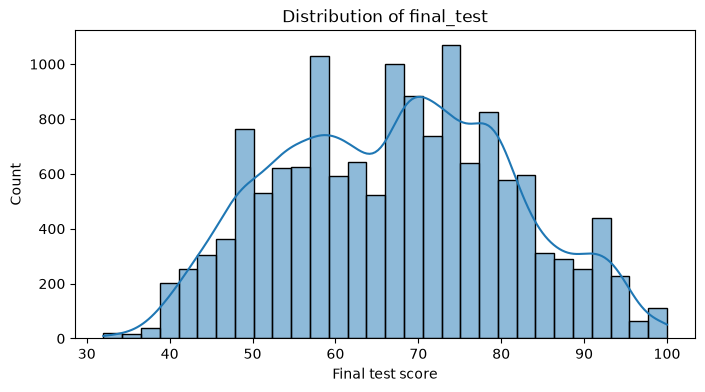

count    14558.0
mean        67.2
std         14.0
min         32.0
25%         56.0
50%         68.0
75%         78.0
max        100.0
Name: final_test, dtype: float64

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(clean_df["final_test"], bins=30, kde=True, ax=ax)
ax.set(title="Distribution of final_test", xlabel="Final test score")
plt.show()

clean_df["final_test"].describe().round(1)

# Scores range from 32 to 100, with a mean of about 67 and a median of 68. The distribution is roughly symmetric without extreme outliers.

# 5. Numerical features vs the target

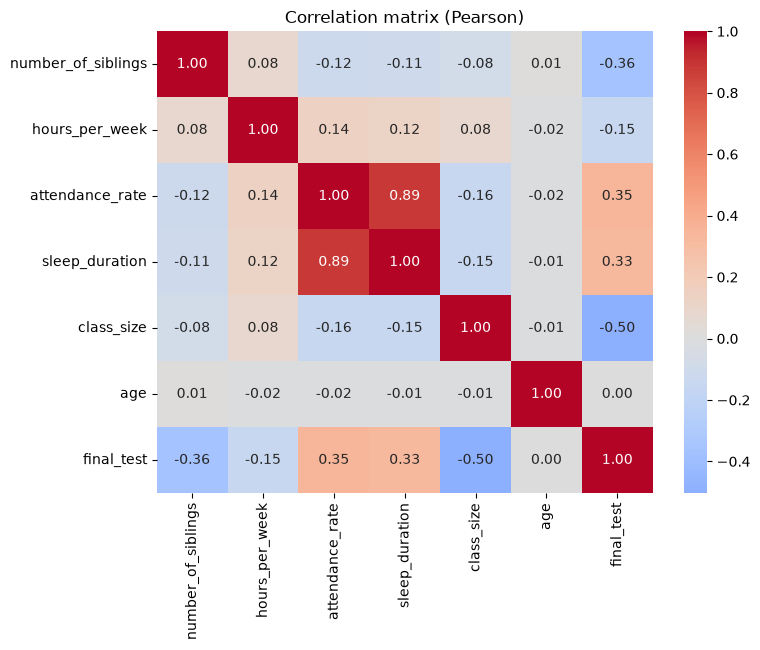

class_size           -0.503722
number_of_siblings   -0.360898
hours_per_week       -0.150763
age                   0.003056
sleep_duration        0.325068
attendance_rate       0.346172
Name: final_test, dtype: float64

In [33]:
num_cols = ["number_of_siblings", "hours_per_week", "attendance_rate",
            "sleep_duration", "class_size", "age", "final_test"]

corr = clean_df[num_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
plt.show()

corr["final_test"].drop("final_test").sort_values()

# `class_size` (r = −0.50) is the strongest predictor: larger classes score lower.
# `number_of_siblings` (−0.36): more siblings, lower scores.
# `attendance_rate` (+0.35) and `sleep_duration` (+0.33): more attendance and more sleep, higher scores.
# `hours_per_week` (−0.15) is weakly negative. One possible reason is that students who are struggling study more.
# `age` (0.00) has no relationship with scores.
# `attendance_rate` and `sleep_duration` are strongly correlated with each other (r = 0.89). See section 6.

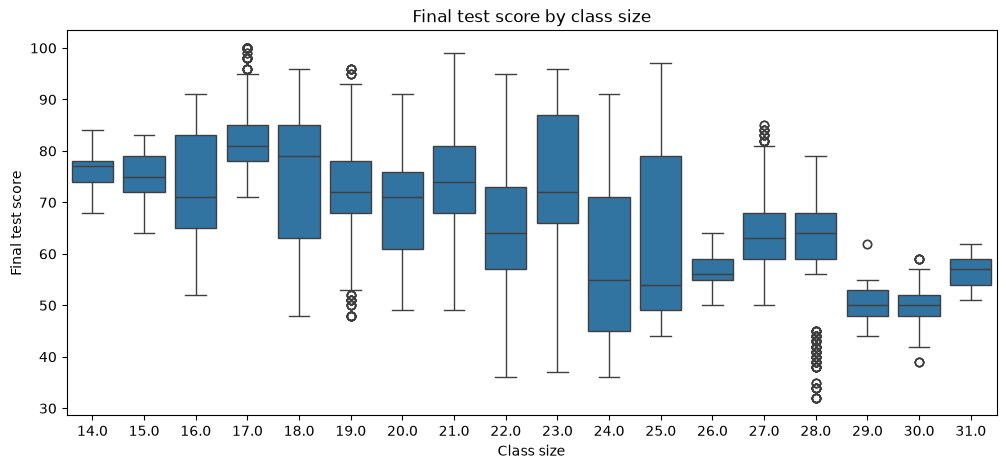

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=clean_df, x="class_size", y="final_test", ax=ax)
ax.set(title="Final test score by class size", xlabel="Class size", ylabel="Final test score")
plt.show()

# The class-size effect is not a straight line. Scores are highest for small classes (around 17–19) and lowest for large classes (28–31), but some sizes (for example 22, 24 and 28) have distinct low-scoring clusters. A linear model can only capture the overall trend, which limits its accuracy and is noted as future work.

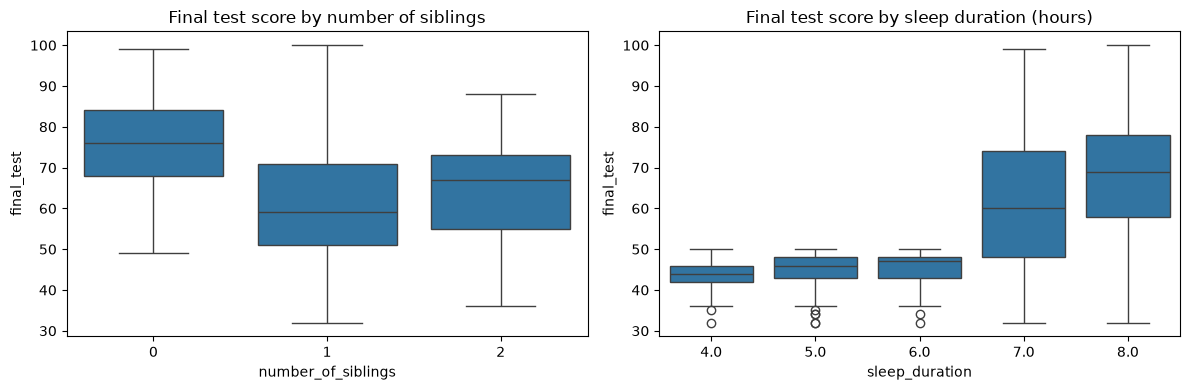

sleep_duration
4.0      136
5.0      214
6.0      218
7.0      598
8.0    13392
Name: count, dtype: int64

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=clean_df, x="number_of_siblings", y="final_test", ax=axes[0])
axes[0].set_title("Final test score by number of siblings")
sns.boxplot(data=clean_df, x="sleep_duration", y="final_test", ax=axes[1])
axes[1].set_title("Final test score by sleep duration (hours)")
plt.tight_layout()
plt.show()

clean_df["sleep_duration"].value_counts().sort_index()

# Each additional sibling is associated with lower scores.
# About 92% of students sleep 8 hours. Scores fall noticeably for the students who sleep less, who are the ones going to bed after midnight.

# 6. Sleep and attendance

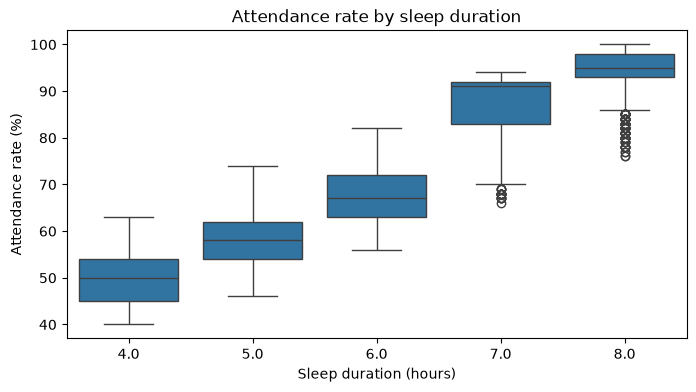

sleep_duration
4.0    50.0
5.0    58.0
6.0    67.0
7.0    91.0
8.0    95.0
Name: attendance_rate, dtype: float64

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=clean_df, x="sleep_duration", y="attendance_rate", ax=ax)
ax.set(title="Attendance rate by sleep duration", xlabel="Sleep duration (hours)", ylabel="Attendance rate (%)")
plt.show()

clean_df.groupby("sleep_duration")["attendance_rate"].median()

# Attendance falls steadily as sleep drops: the median is about 95% at 8 hours and about 50% at 4 hours, roughly 10 points per hour of lost sleep. The groups barely overlap.

# impute missing `attendance_rate` with the median for the student's sleep-duration group, not the overall median. The medians are learned from the training set only, after the split, to avoid data leakage.

# 7. Categorical features vs the target

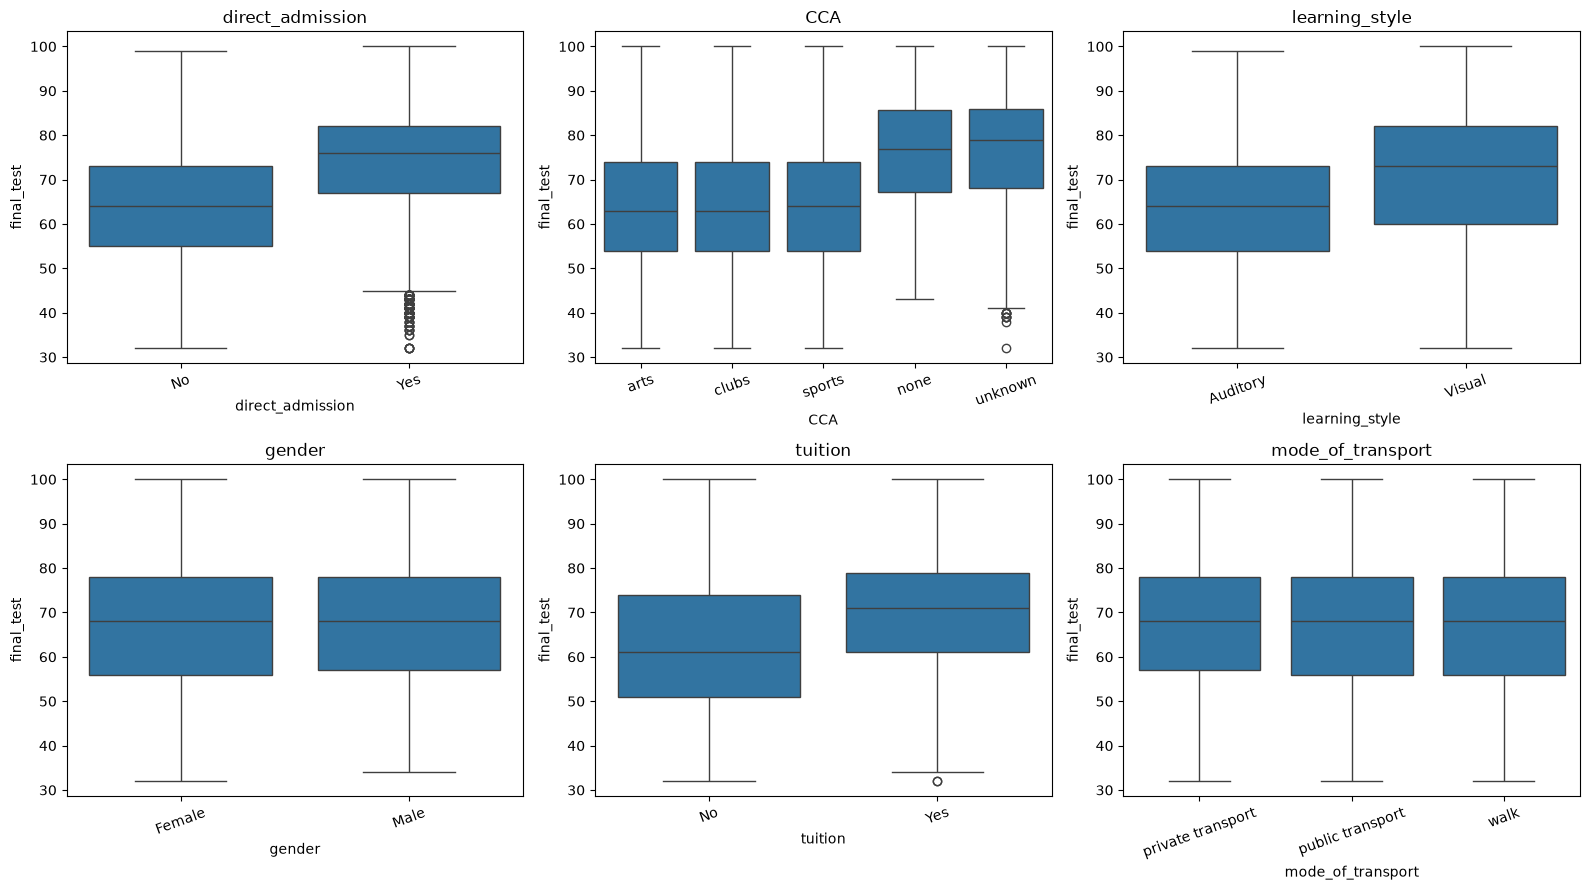

In [37]:
cat_cols = ["direct_admission", "CCA", "learning_style", "gender", "tuition", "mode_of_transport"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, ax in zip(cat_cols, axes.flat):
    order = clean_df.groupby(col)["final_test"].median().sort_values().index
    sns.boxplot(data=clean_df, x=col, y="final_test", order=order, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# 8. Summary of findings and pipeline decisions

# 495 rows missing the target
# 846 repeat student records
# `bag_color` varies randomly - Drop
# Inconsistent `CCA` / `tuition` labels - Standardise
# Missing `CCA` (24%) behaves like `none` - Fill as `"unknown"`
# Invalid ages (6, 5, -5, -4) - Correct to 15 / 16, drop the single -4 record
# Sleep and wake times stored as strings - Engineer `sleep_duration`
# `n_male` and `n_female` relate to scores mainly through class size - Engineer `class_size`
# `class_size` is the strongest predictor but non-linear
# Attendance strongly linked to sleep (r = 0.89) - Impute attendance by sleep group, using training medians only
# `age`, `gender`, `mode_of_transport` barely relate to scores - Kept for now, candidates for removal
# `index`, `student_id` are identifiers - Drop

# Modelling implications
# This is a regression problem with a roughly symmetric target, so linear regression is a reasonable starting point.
# Numerical features are on different scales, so they are standardised. This matters for Ridge and Lasso, which penalise coefficients.
# Categorical features are one-hot encoded, with `drop="if_binary"` to avoid the dummy-variable trap.
# The non-linear class-size effect means a linear model will leave some variation unexplained. Tree-based models are a natural next step.